In [1]:
from matplotlib import pyplot
import matplotlib.pyplot as plt
import numpy as np
from keras.applications.vgg16 import VGG16

2025-11-13 00:03:06.593172: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
#Load the model
model = VGG16()
model.summary()

I0000 00:00:1762972389.525748   35184 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6145 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2070, pci bus id: 0000:01:00.0, compute capability: 7.5


553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 50s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# from keras.utils import plot_model

# plot_model(model)

In [4]:
from tensorflow.keras.layers import Conv2D, Dense

for i, layer in enumerate(model.layers):
    # Check if layer is instance of Conv2D or Dense
    if isinstance(layer, (Conv2D, Dense)):
        weights = layer.get_weights()
        if len(weights) > 0:
            filters_or_weights, biases = weights
            print(f"Layer number {i}, name: {layer.name}, weights shape: {filters_or_weights.shape}")
        else:
            print(f"Layer number {i}, name: {layer.name} has no weights")

Layer number 1, name: block1_conv1, weights shape: (3, 3, 3, 64)
Layer number 2, name: block1_conv2, weights shape: (3, 3, 64, 64)
Layer number 4, name: block2_conv1, weights shape: (3, 3, 64, 128)
Layer number 5, name: block2_conv2, weights shape: (3, 3, 128, 128)
Layer number 7, name: block3_conv1, weights shape: (3, 3, 128, 256)
Layer number 8, name: block3_conv2, weights shape: (3, 3, 256, 256)
Layer number 9, name: block3_conv3, weights shape: (3, 3, 256, 256)
Layer number 11, name: block4_conv1, weights shape: (3, 3, 256, 512)
Layer number 12, name: block4_conv2, weights shape: (3, 3, 512, 512)
Layer number 13, name: block4_conv3, weights shape: (3, 3, 512, 512)
Layer number 15, name: block5_conv1, weights shape: (3, 3, 512, 512)
Layer number 16, name: block5_conv2, weights shape: (3, 3, 512, 512)
Layer number 17, name: block5_conv3, weights shape: (3, 3, 512, 512)
Layer number 20, name: fc1, weights shape: (25088, 4096)
Layer number 21, name: fc2, weights shape: (4096, 4096)
Lay

In [5]:
# retrieve weights from the second hidden layer
filters , bias = model.layers[1].get_weights()

In [6]:
# normalize filter values to 0-1 so we can visualize them
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

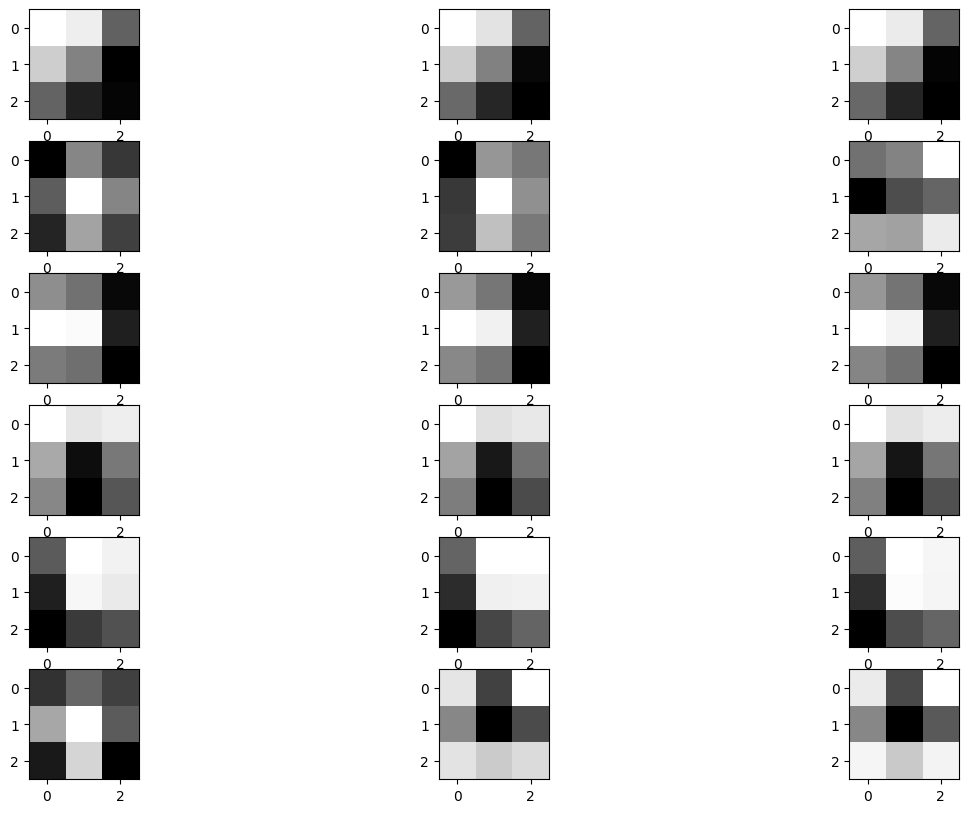

In [7]:
n_filters = 6
ix=1
fig = plt.figure(figsize=(15,10))
for i in range(n_filters):
    # get the filters
    f = filters[:,:,:,i]
    for j in range(3):
        # subplot for 6 filters and 3 channels
        plt.subplot(n_filters,3,ix)
        plt.imshow(f[:,:,j] ,cmap='gray')
        ix+=1
#plot the filters
plt.show()

In [8]:
from tensorflow.keras.models import Model
model = Model(inputs=model.inputs , outputs=model.layers[1].output)

In [10]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.resnet import preprocess_input

# Load and preprocess the image
image = load_img("/home/here_im/ARPAN/deep_learning/CNNs/Virat Kohli Pc Wallpaper 4k Hd.jpeg", target_size=(224, 224))
# convert the image to an array
image = img_to_array(image)
# expand dimensions so that it represents a single 'sample'
image = np.expand_dims(image, axis=0)
image = preprocess_input(image)


2025-11-13 00:04:27.966805: I external/local_xla/xla/service/service.cc:163] XLA service 0x7c7714003500 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-11-13 00:04:27.966822: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 2070, Compute Capability 7.5
2025-11-13 00:04:27.972196: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-13 00:04:27.986533: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91400


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step


I0000 00:00:1762972468.233125   35259 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


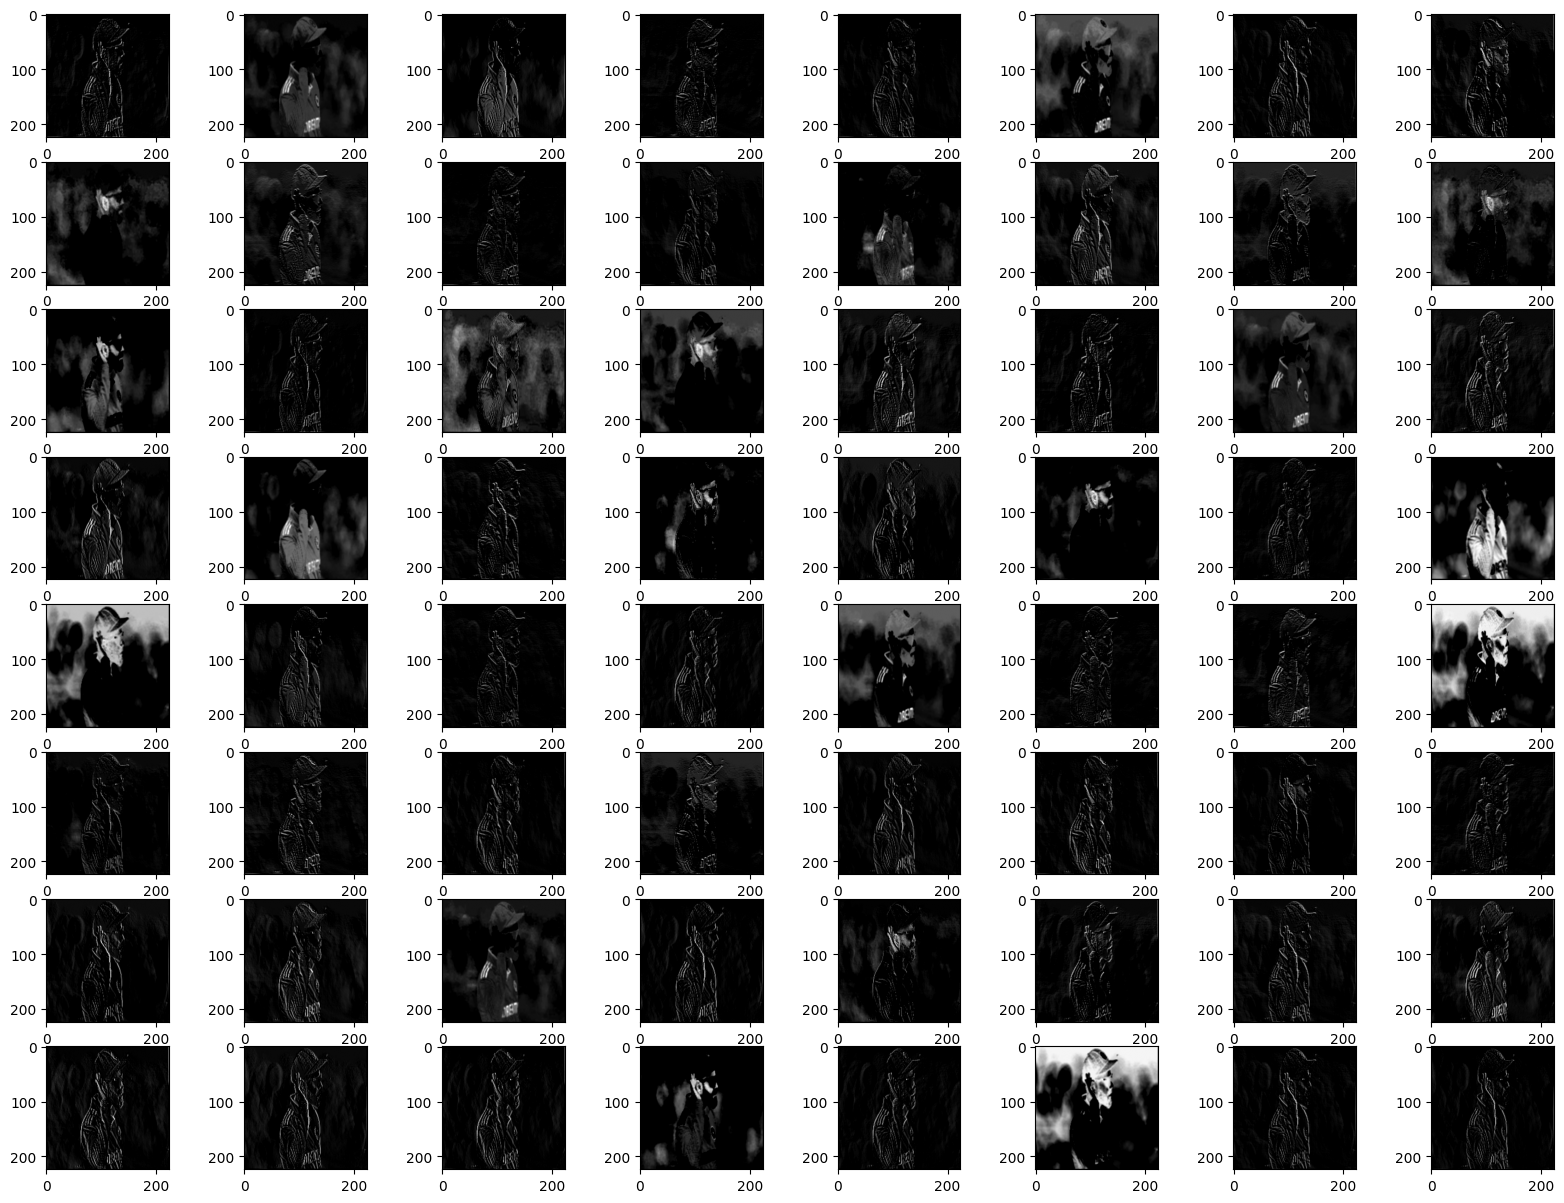

In [11]:
#calculating features_map
features = model.predict(image)

fig = plt.figure(figsize=(20,15))
for i in range(1,features.shape[3]+1):

    plt.subplot(8,8,i)
    plt.imshow(features[0,:,:,i-1] , cmap='gray')

plt.show()

In [12]:
model2 = VGG16()

In [13]:
layer_index = [ 1, 2, 4, 5, 7, 8, 9, 11, 12, 13, 15, 16, 17, 20, 21, 22] # Total 16 layers
outputs = [model2.layers[i].output for i in layer_index]

model3 = Model( inputs= model2.inputs, outputs = outputs)

2025-11-13 00:04:49.423241: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=2} for conv (f32[1,512,28,28]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,256,28,28]{3,2,1,0}, f32[512,256,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]}
2025-11-13 00:04:49.508298: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=2} for conv (f32[1,512,28,28]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,512,28,28]{3,2,1,0}, f32[512,512,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_targe

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Layer 1 output shape: (1, 224, 224, 64)


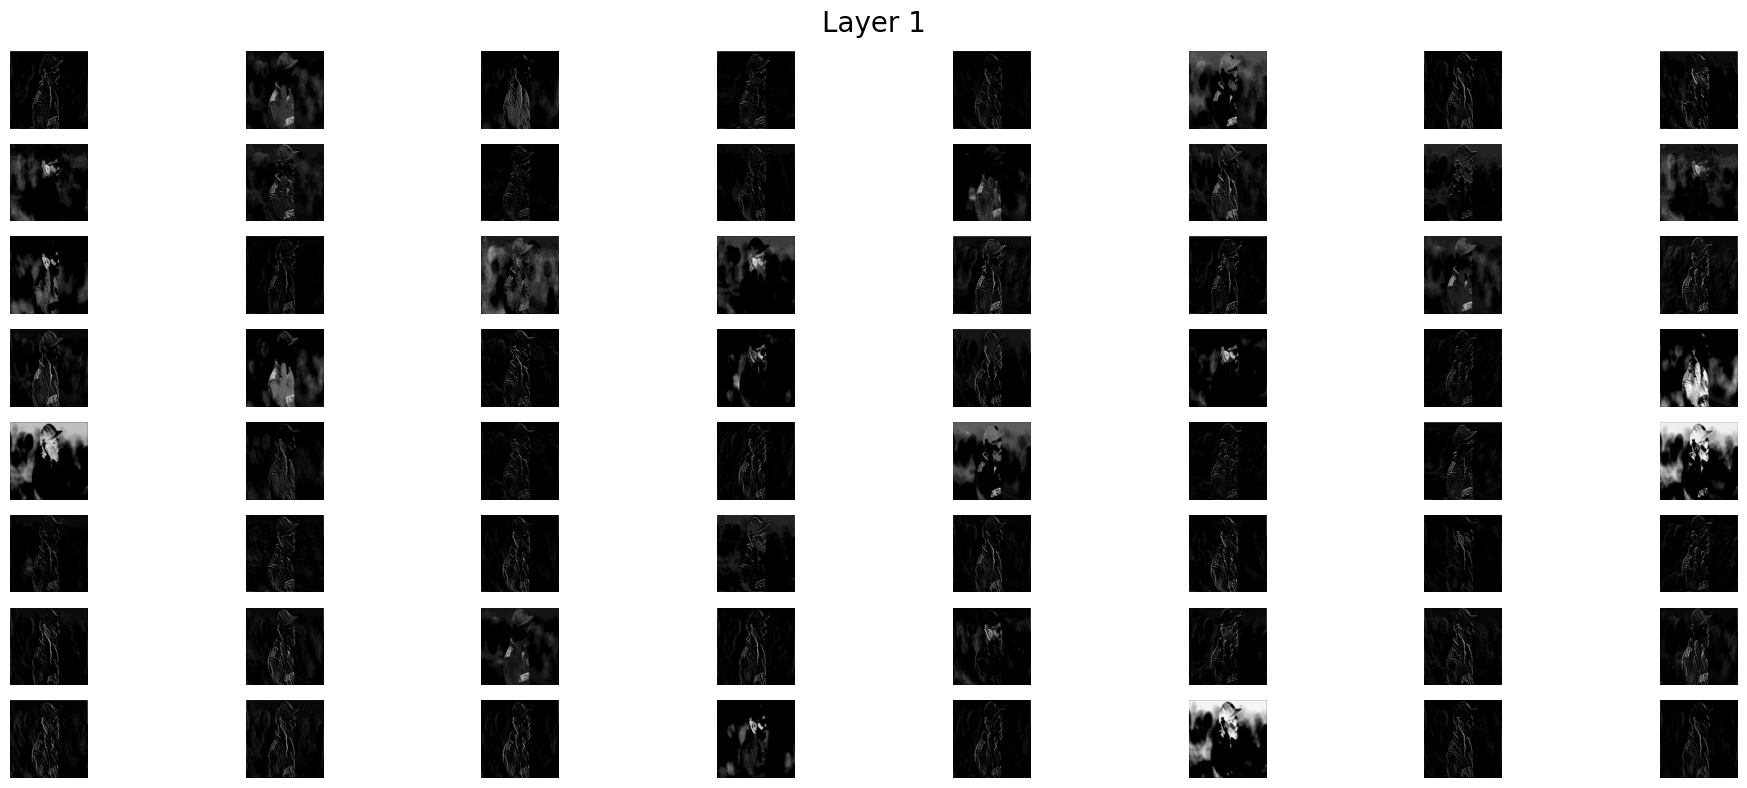

Layer 2 output shape: (1, 224, 224, 64)


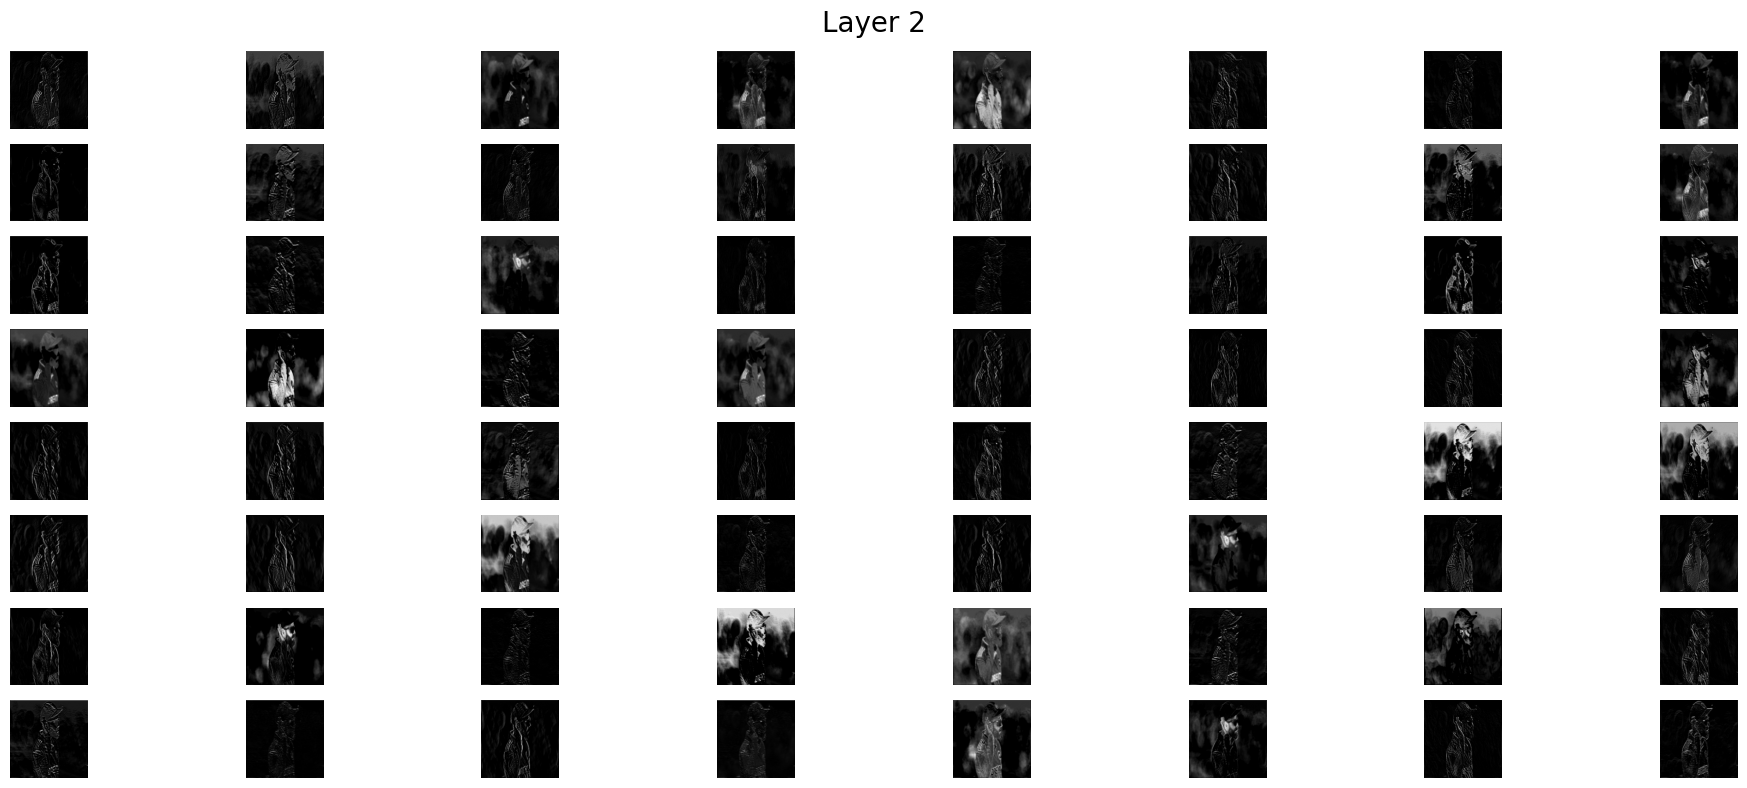

Layer 4 output shape: (1, 112, 112, 128)


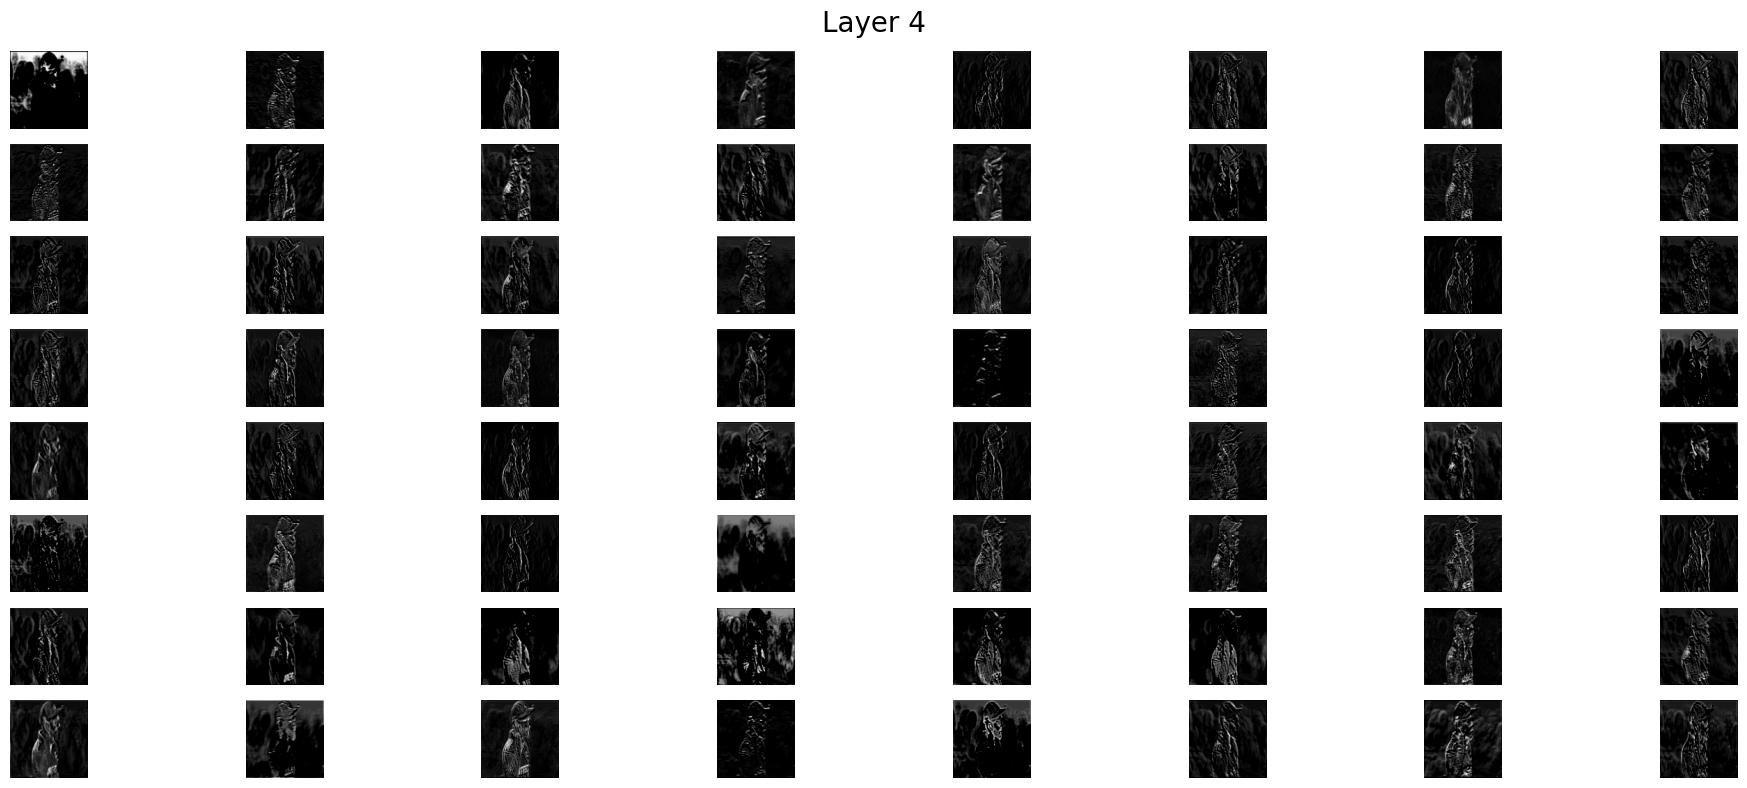

Layer 5 output shape: (1, 112, 112, 128)


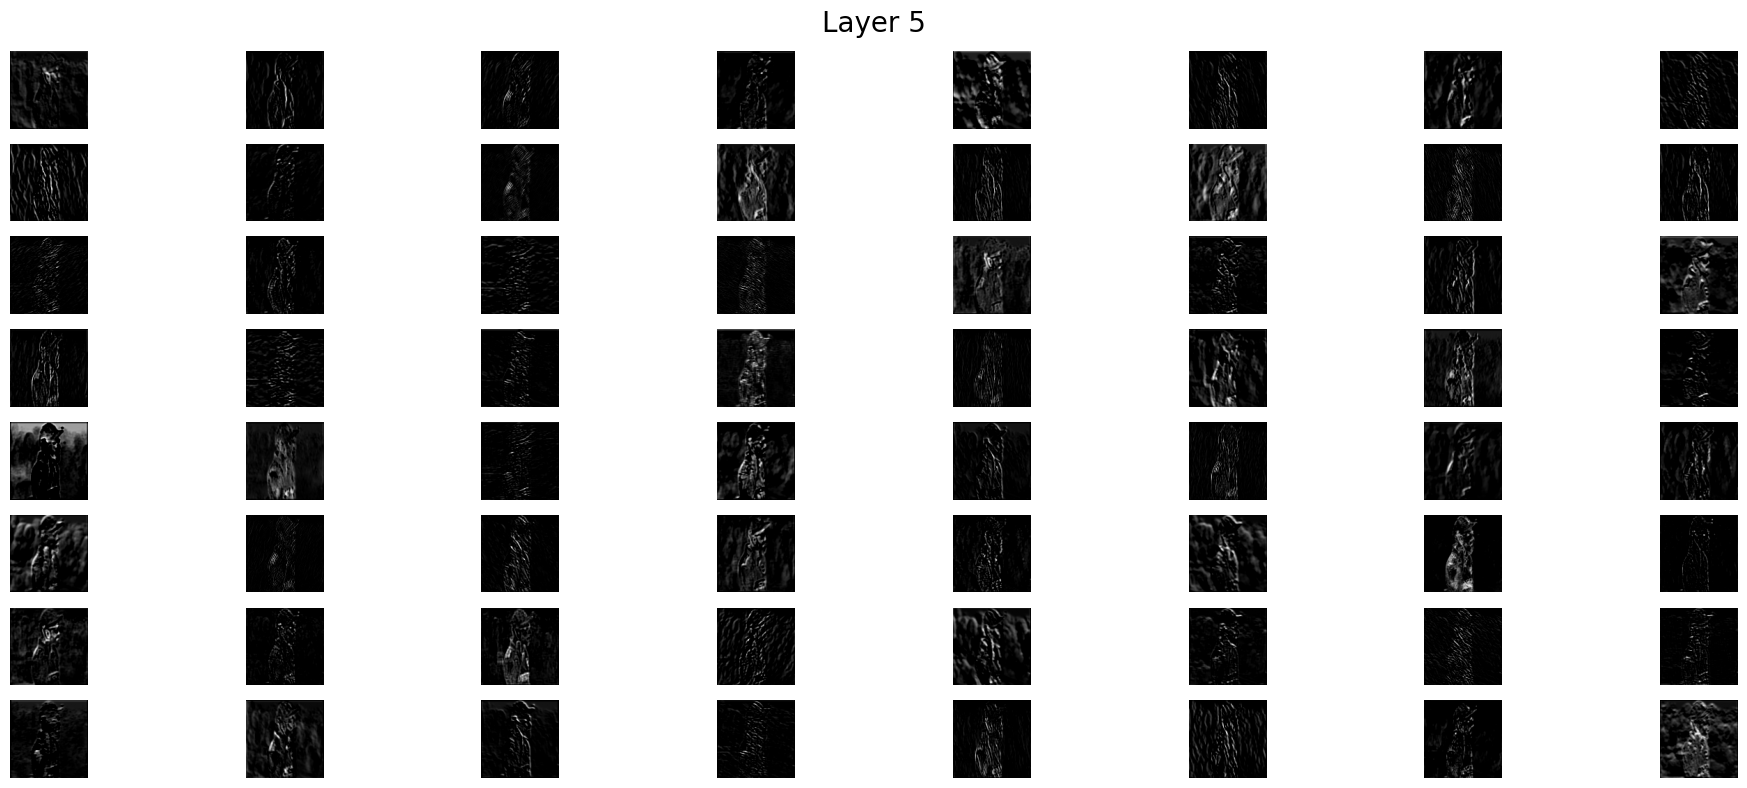

Layer 7 output shape: (1, 56, 56, 256)


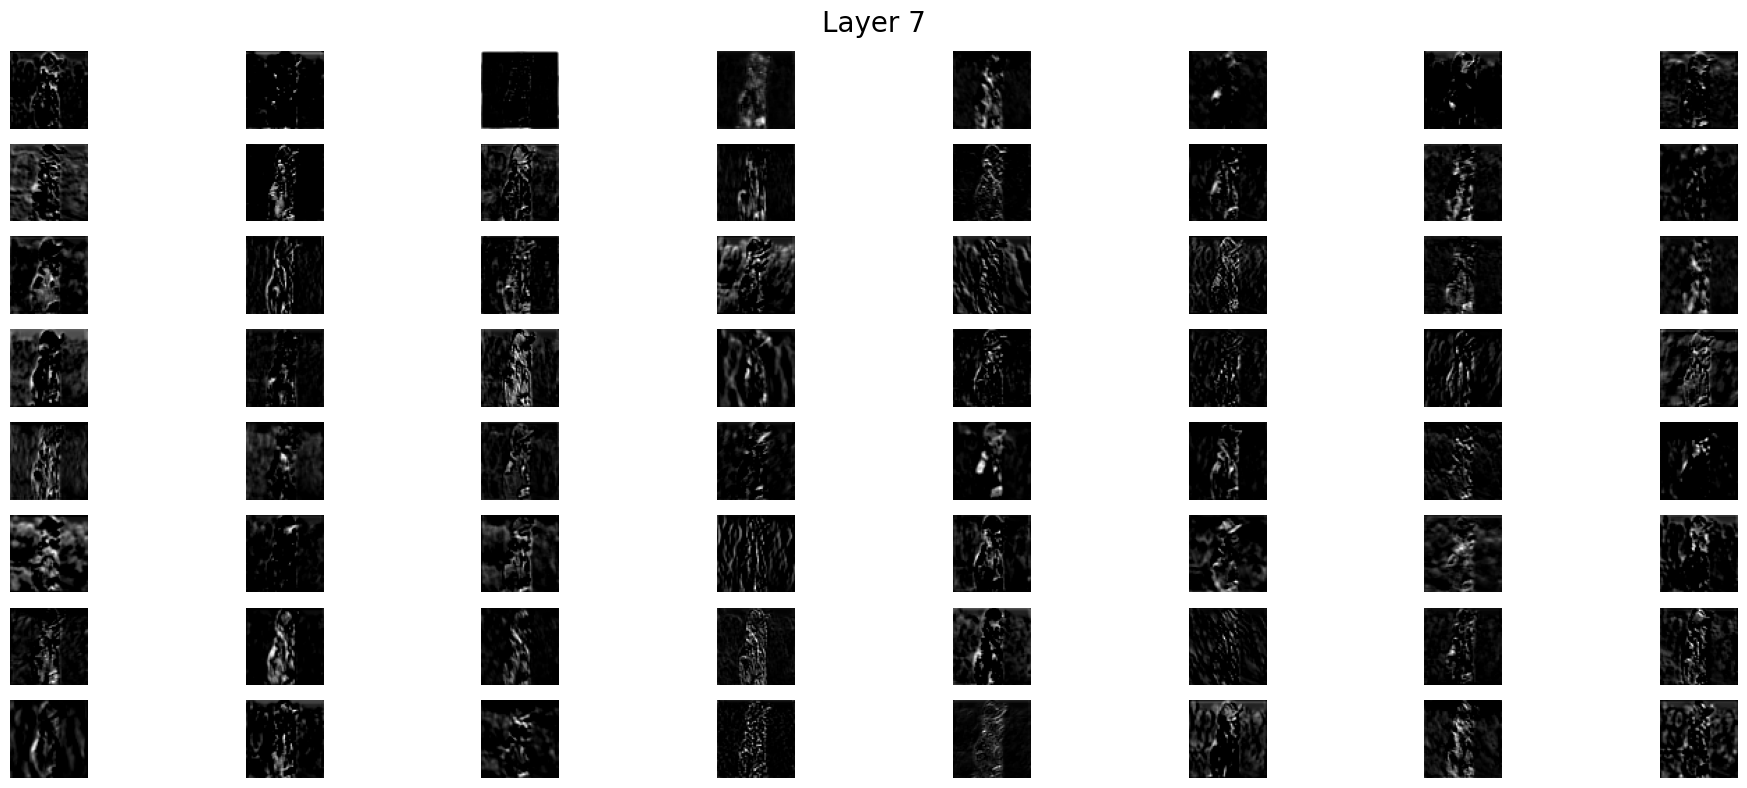

Layer 8 output shape: (1, 56, 56, 256)


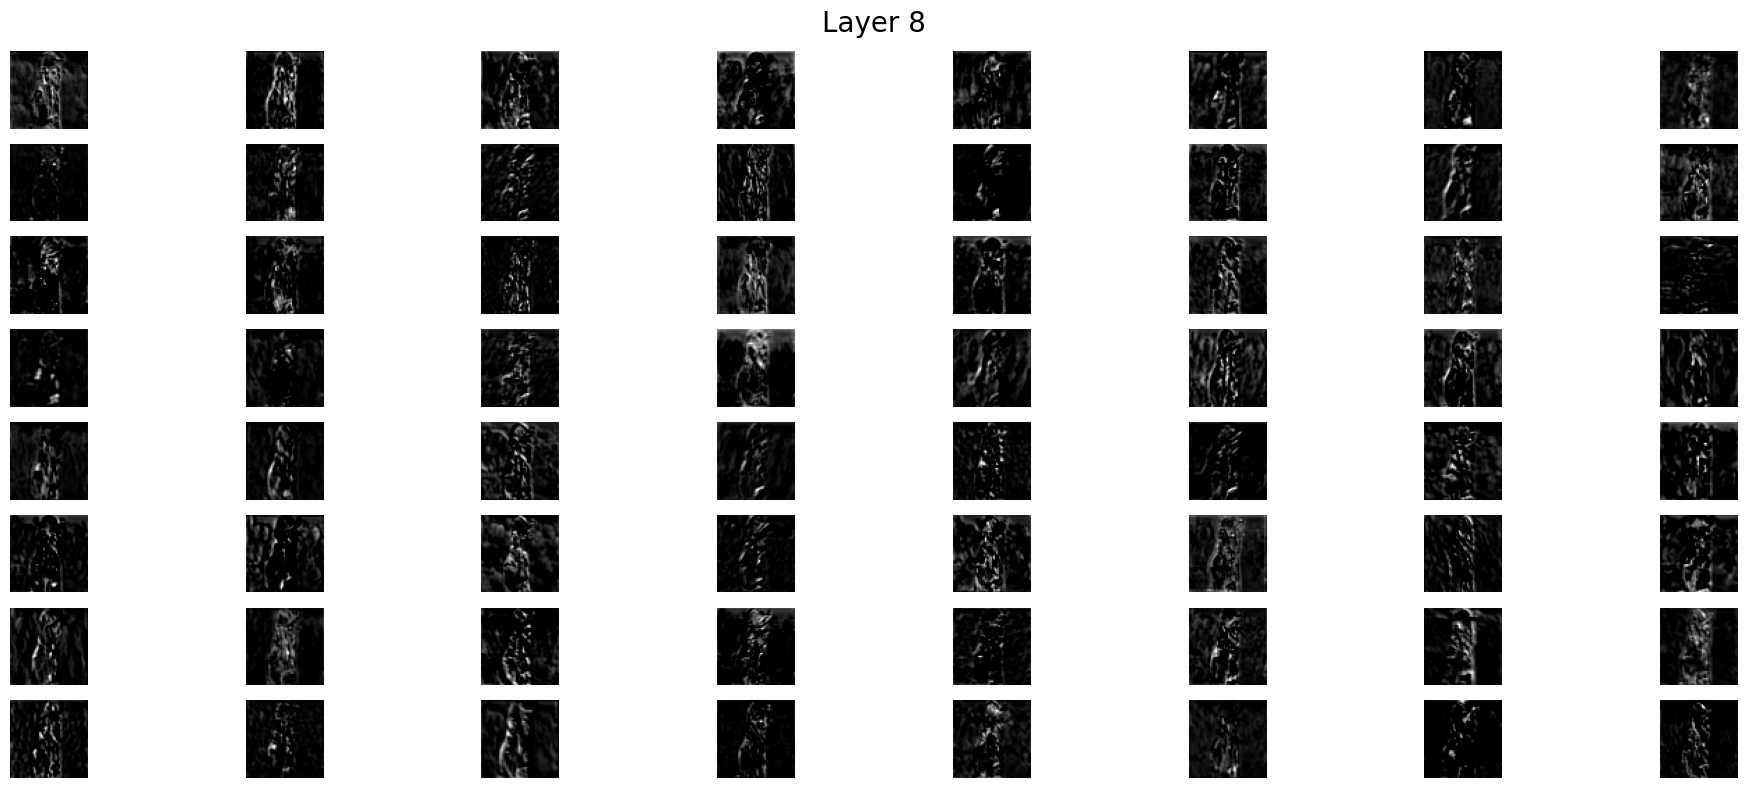

Layer 9 output shape: (1, 56, 56, 256)


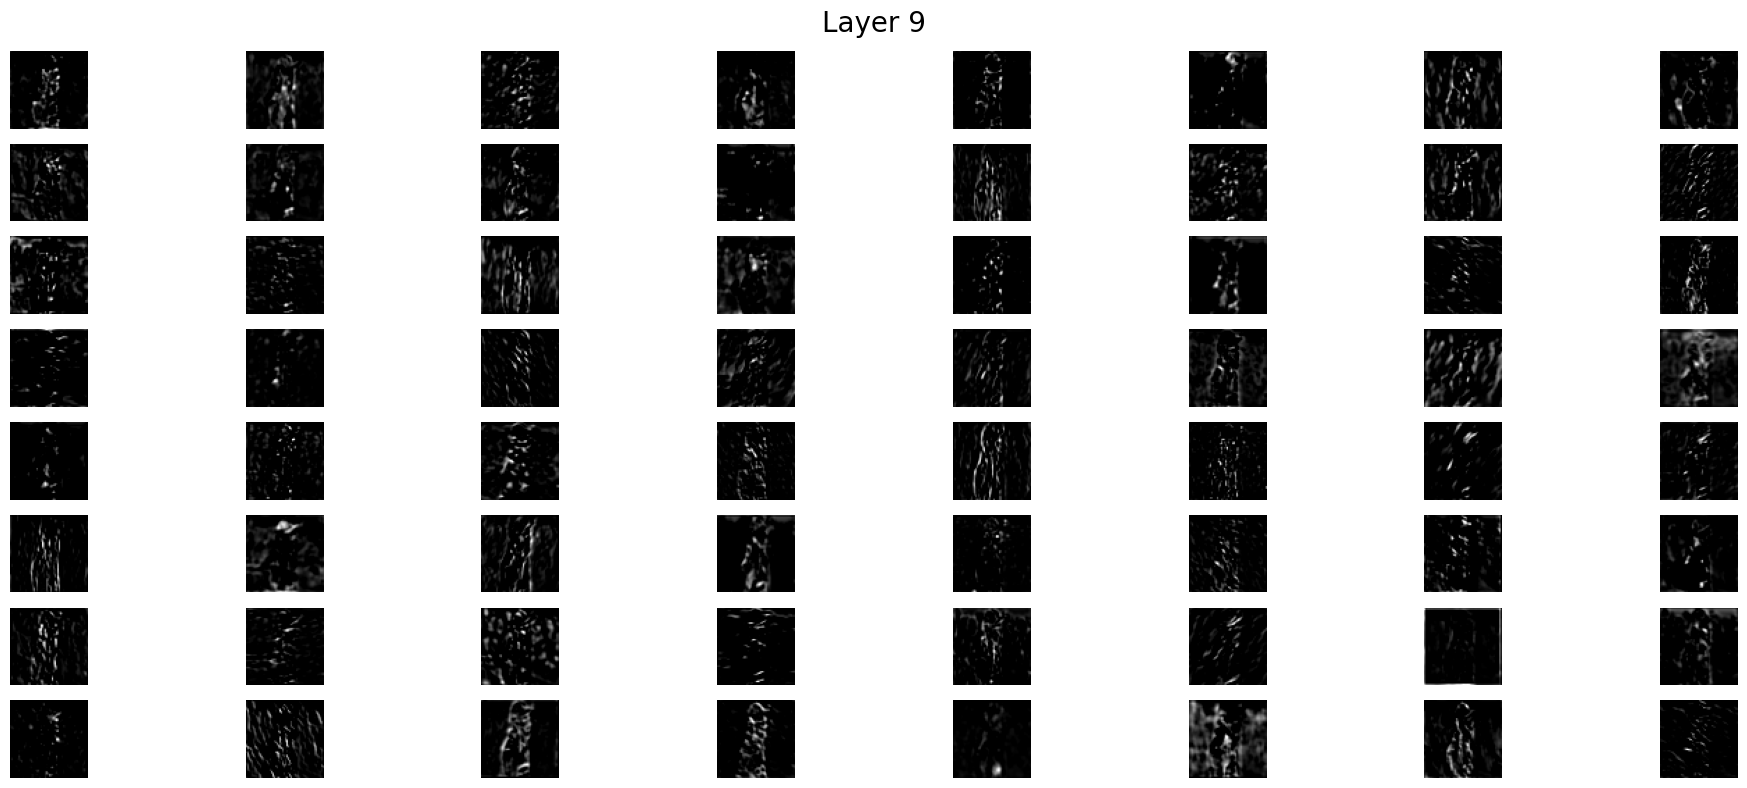

Layer 11 output shape: (1, 28, 28, 512)


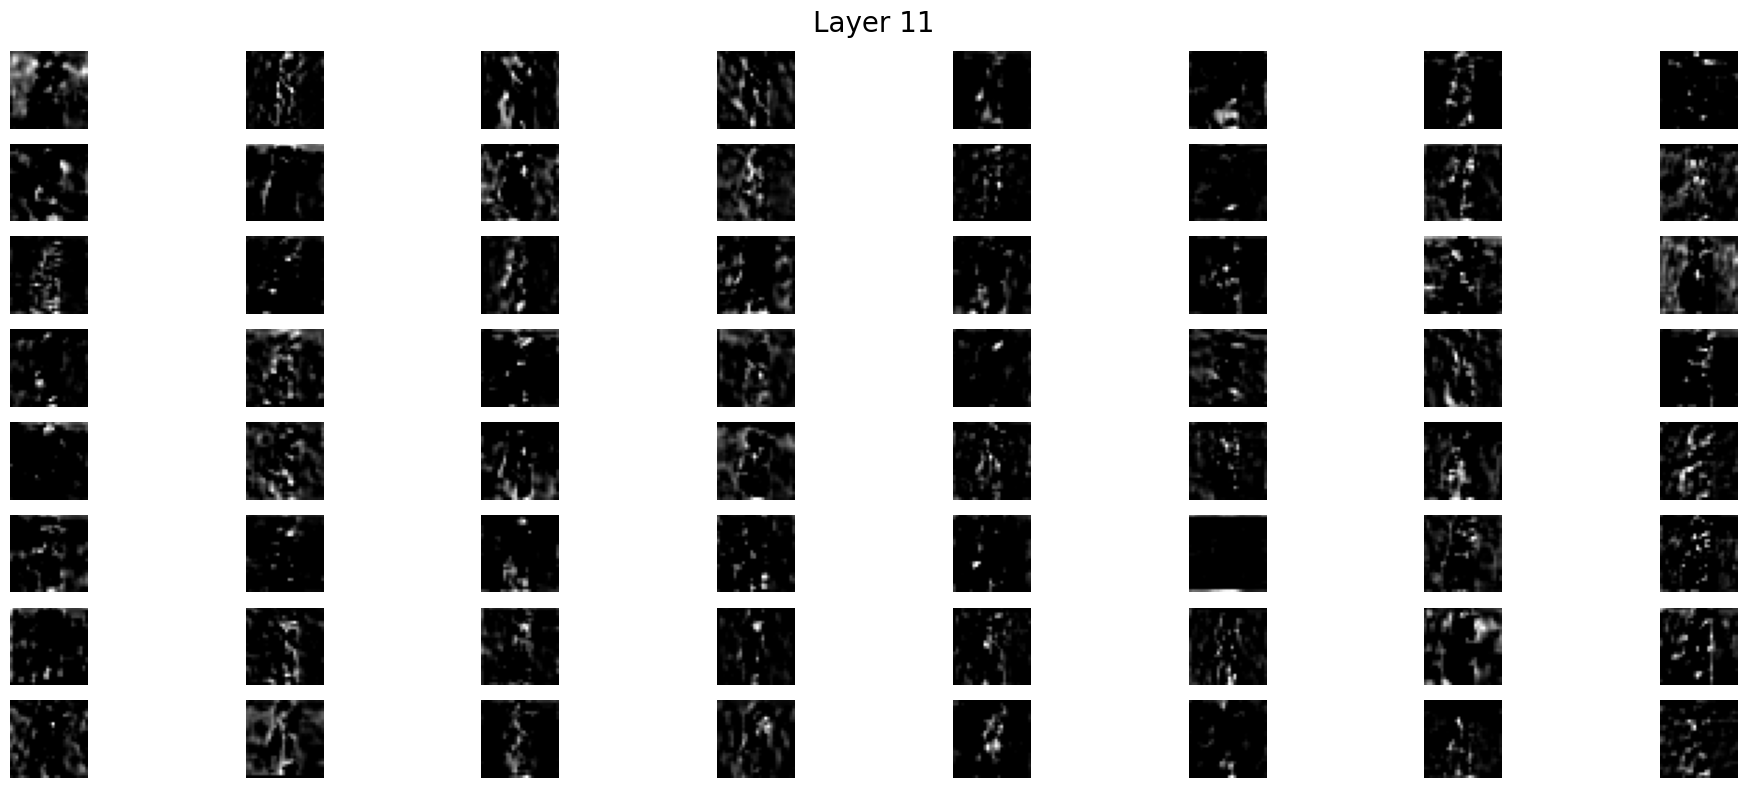

Layer 12 output shape: (1, 28, 28, 512)


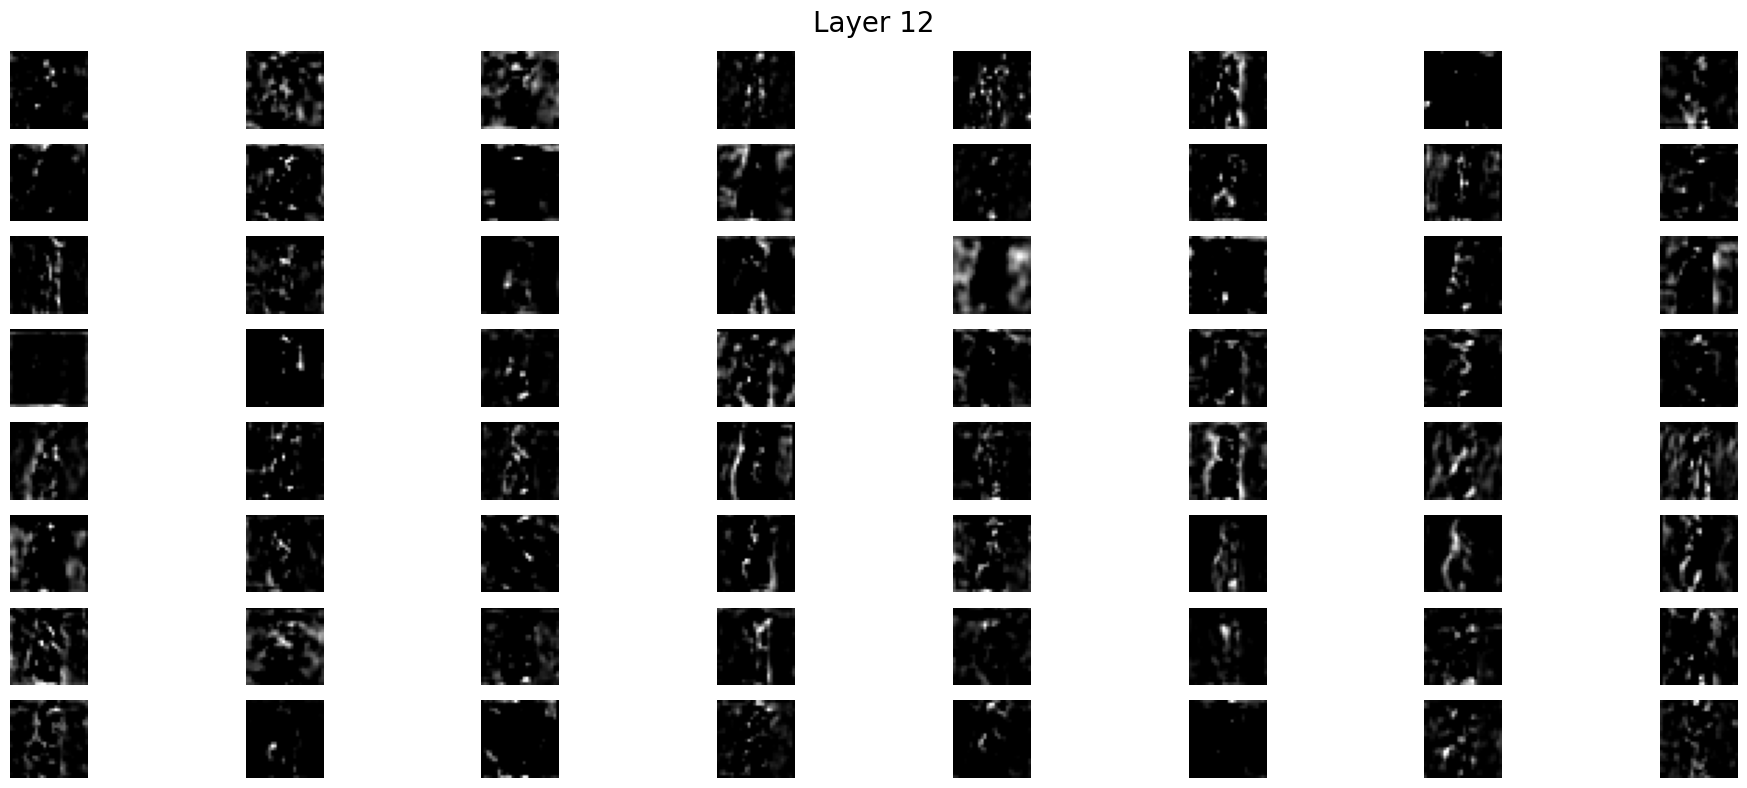

Layer 13 output shape: (1, 28, 28, 512)


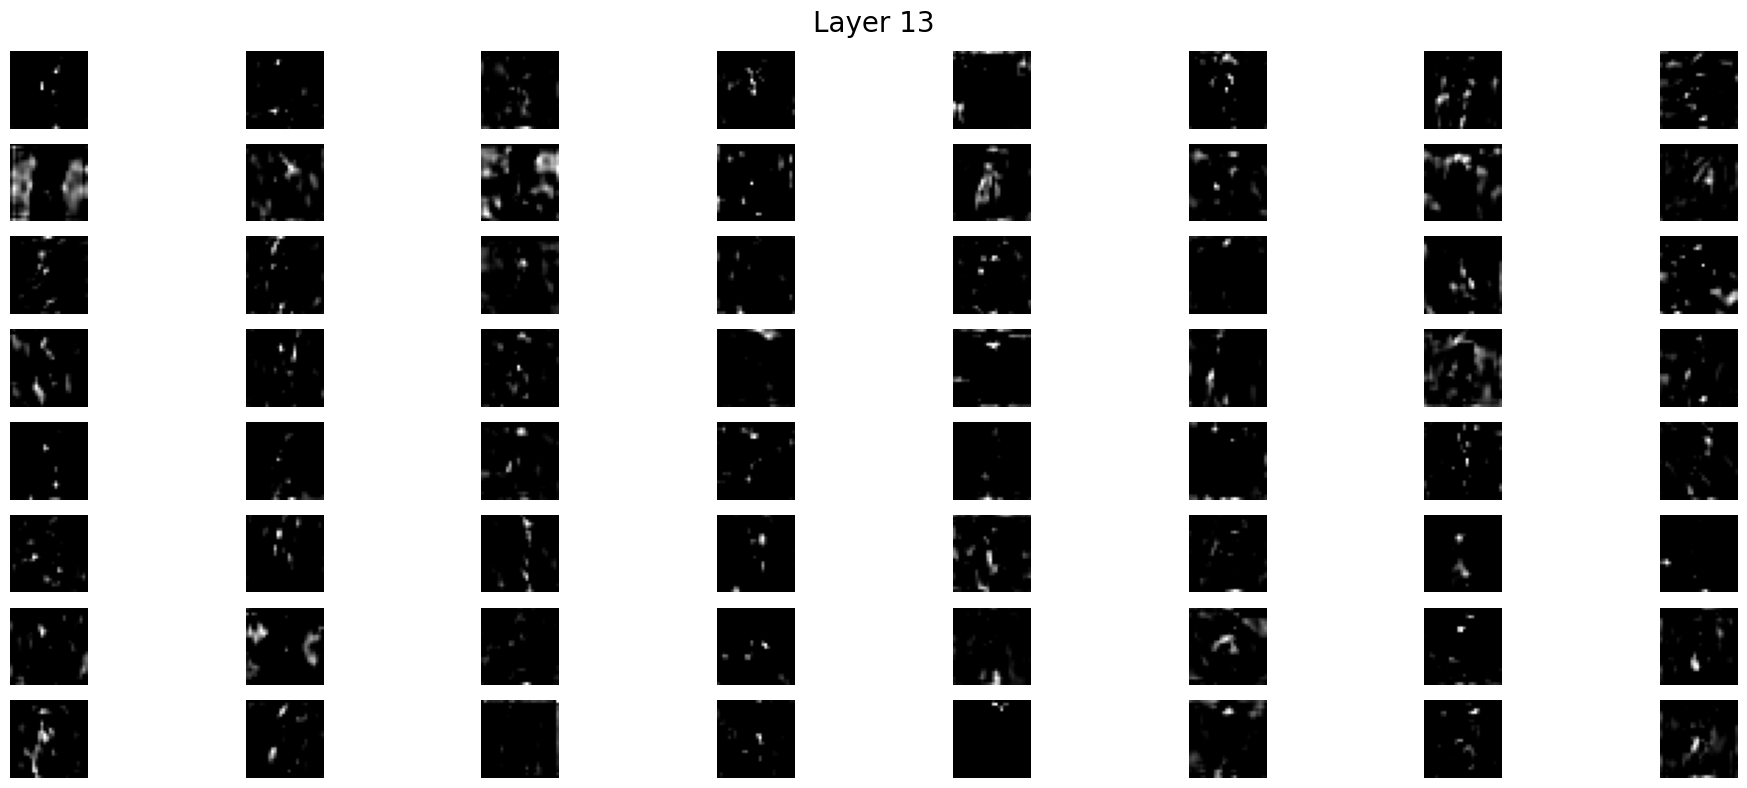

Layer 15 output shape: (1, 14, 14, 512)


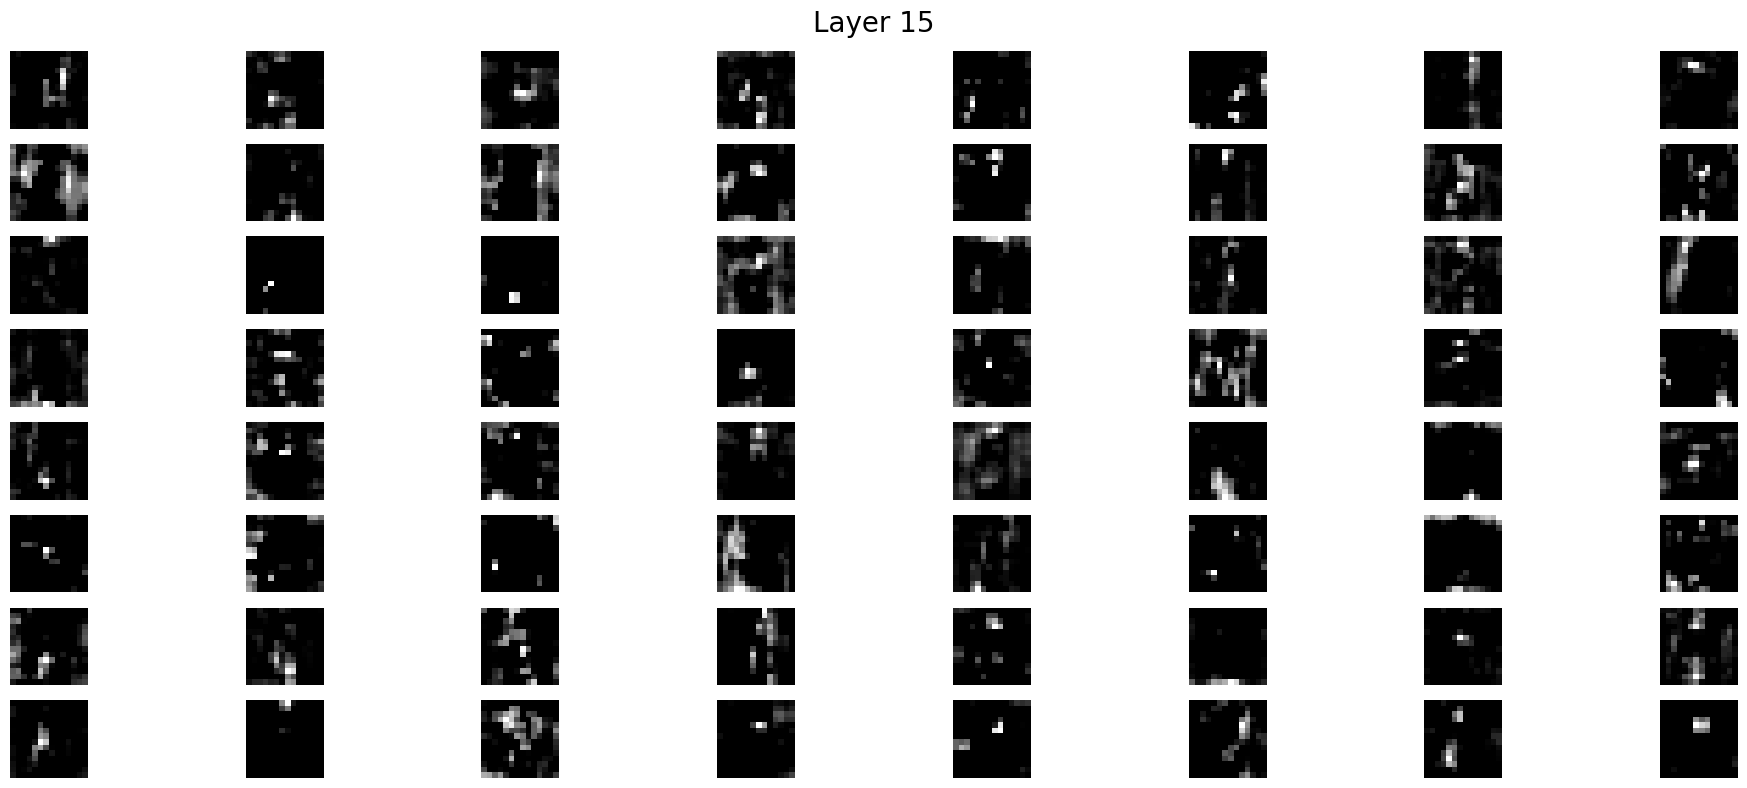

Layer 16 output shape: (1, 14, 14, 512)


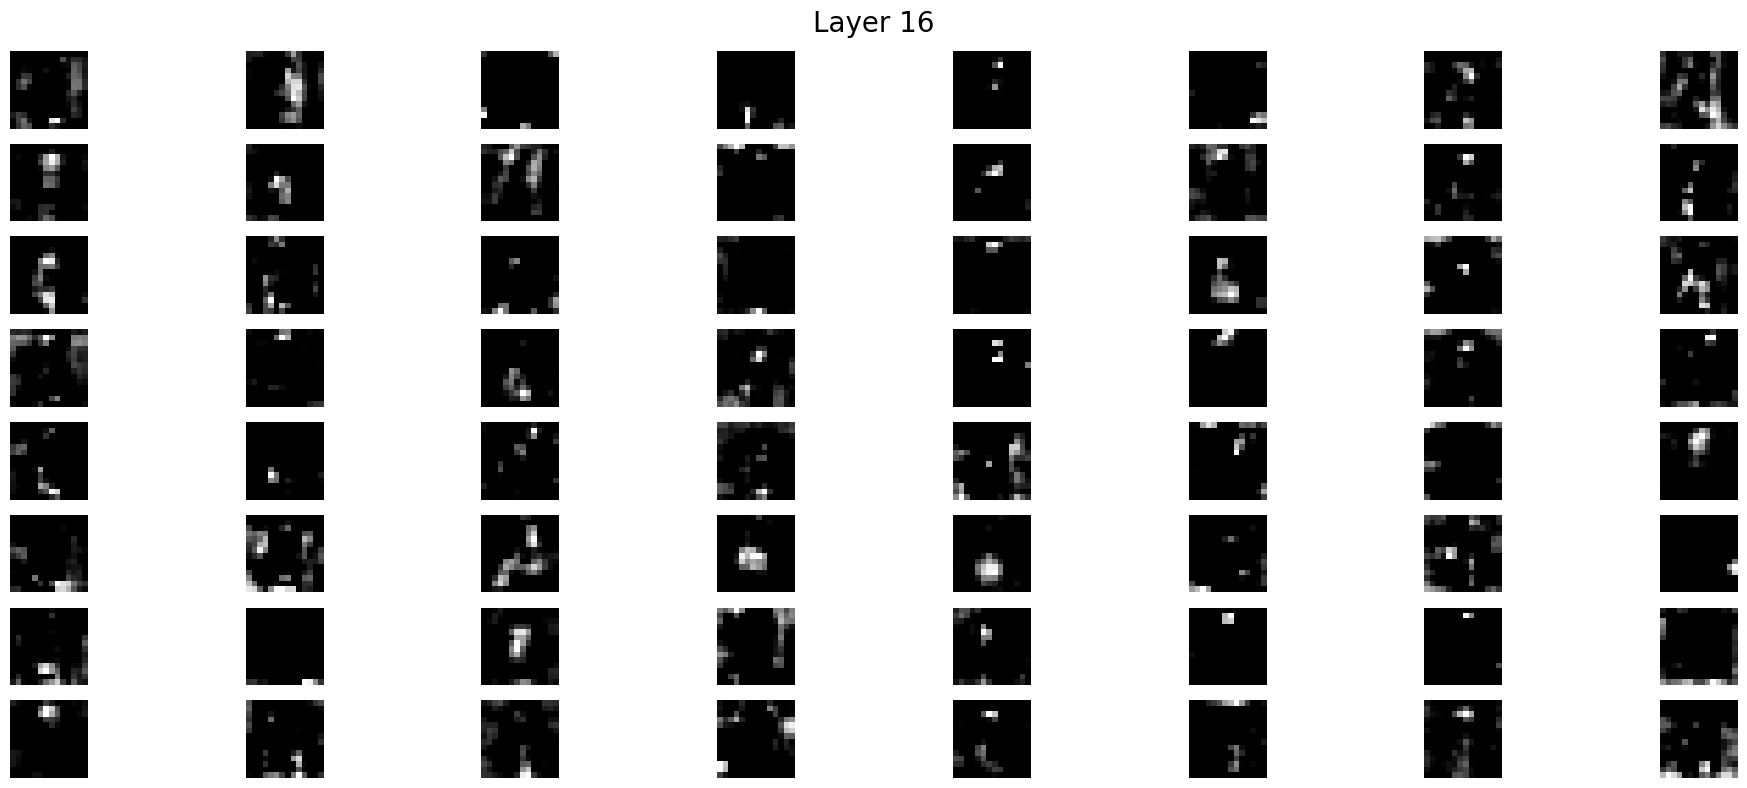

Layer 17 output shape: (1, 14, 14, 512)


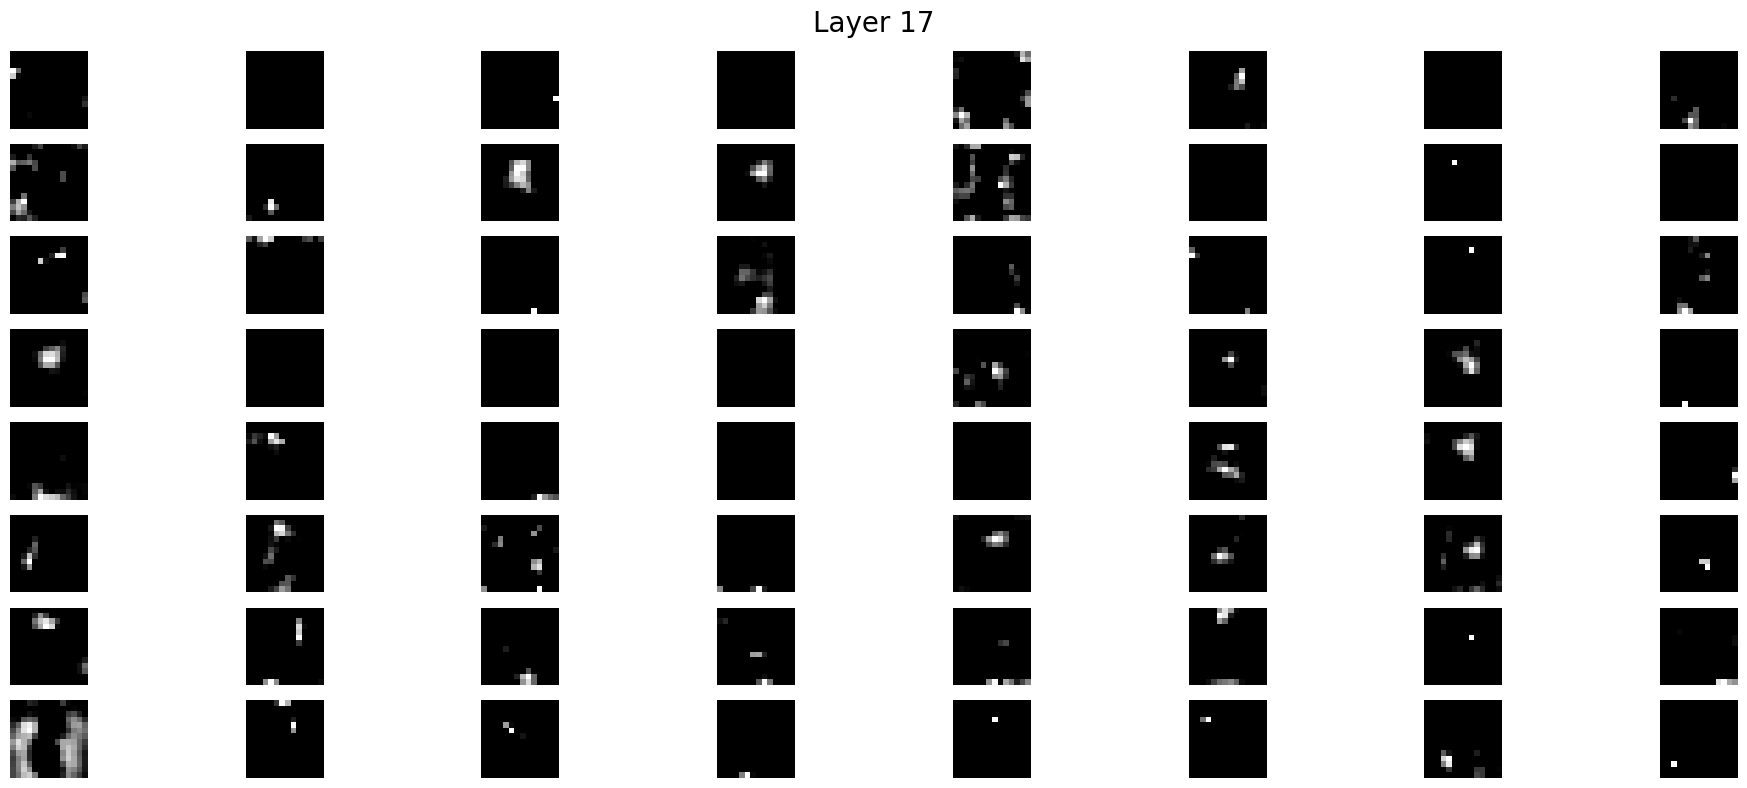

Layer 20 output shape: (1, 4096)


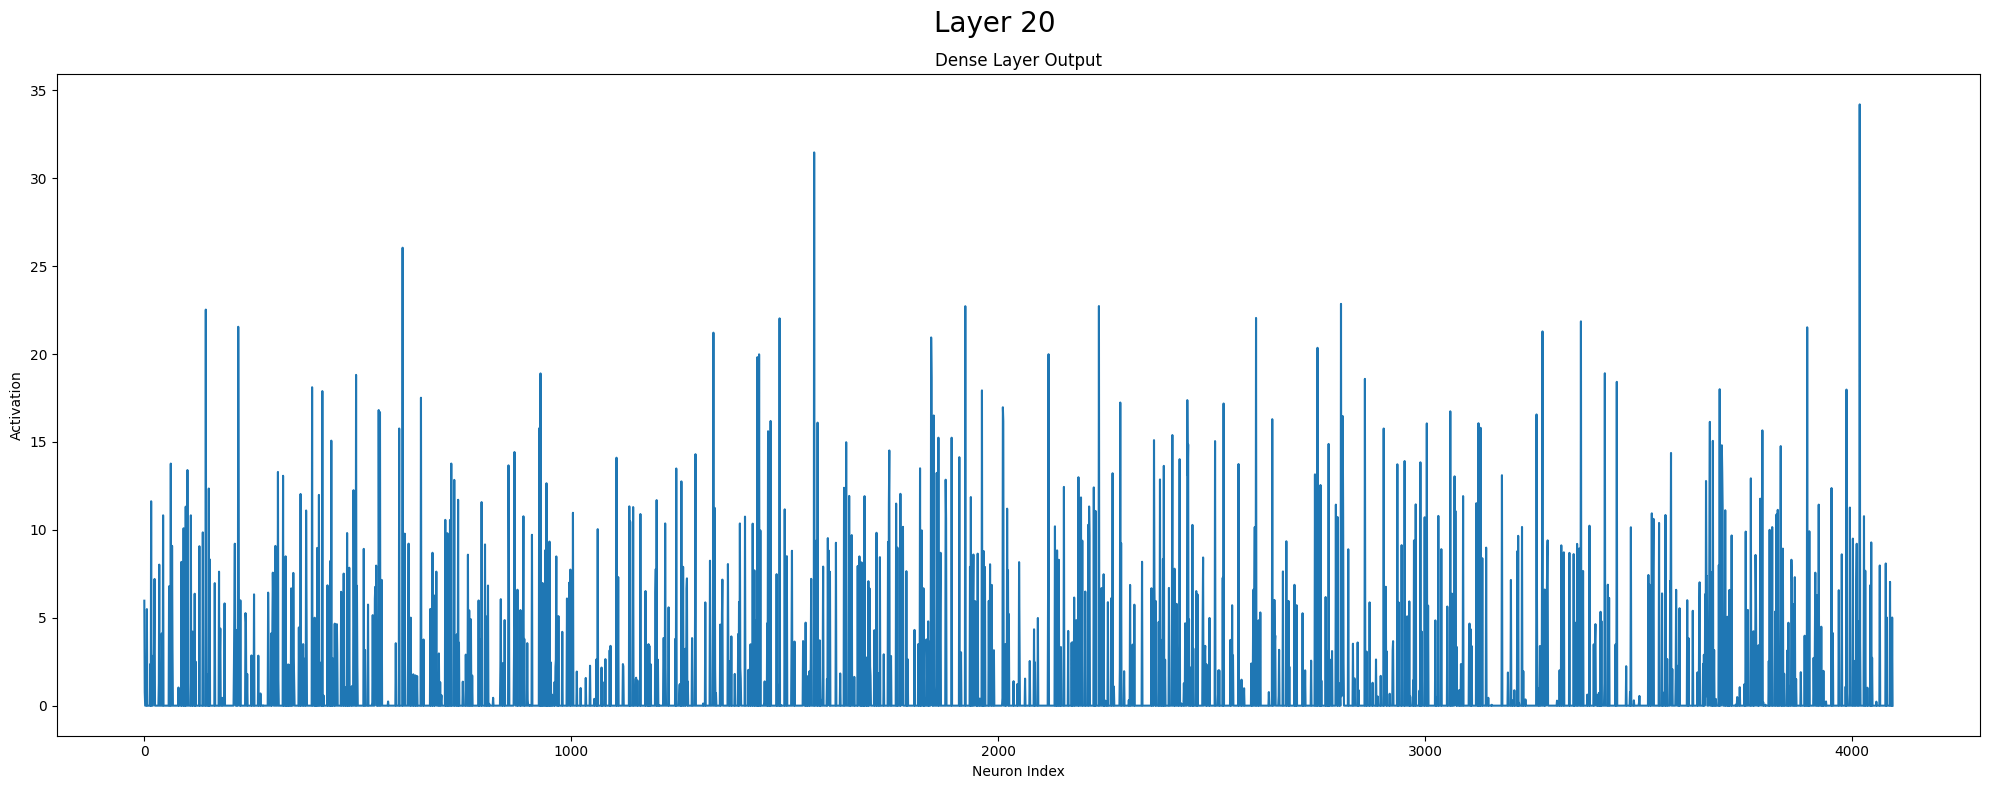

Layer 21 output shape: (1, 4096)


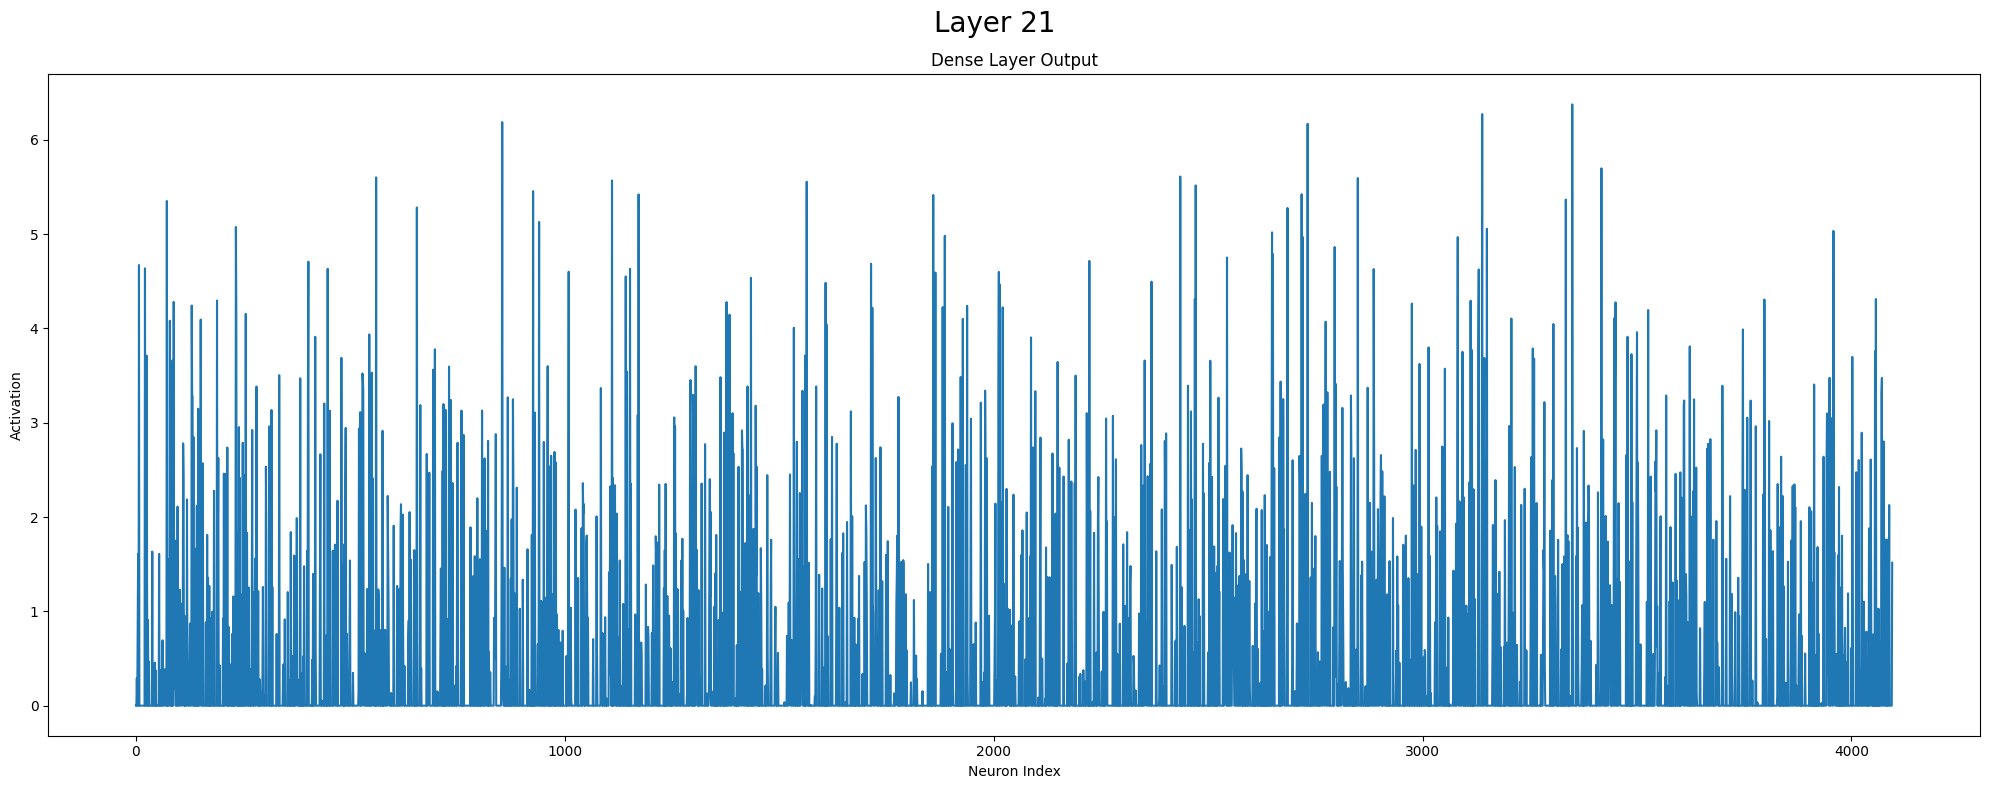

Layer 22 output shape: (1, 1000)


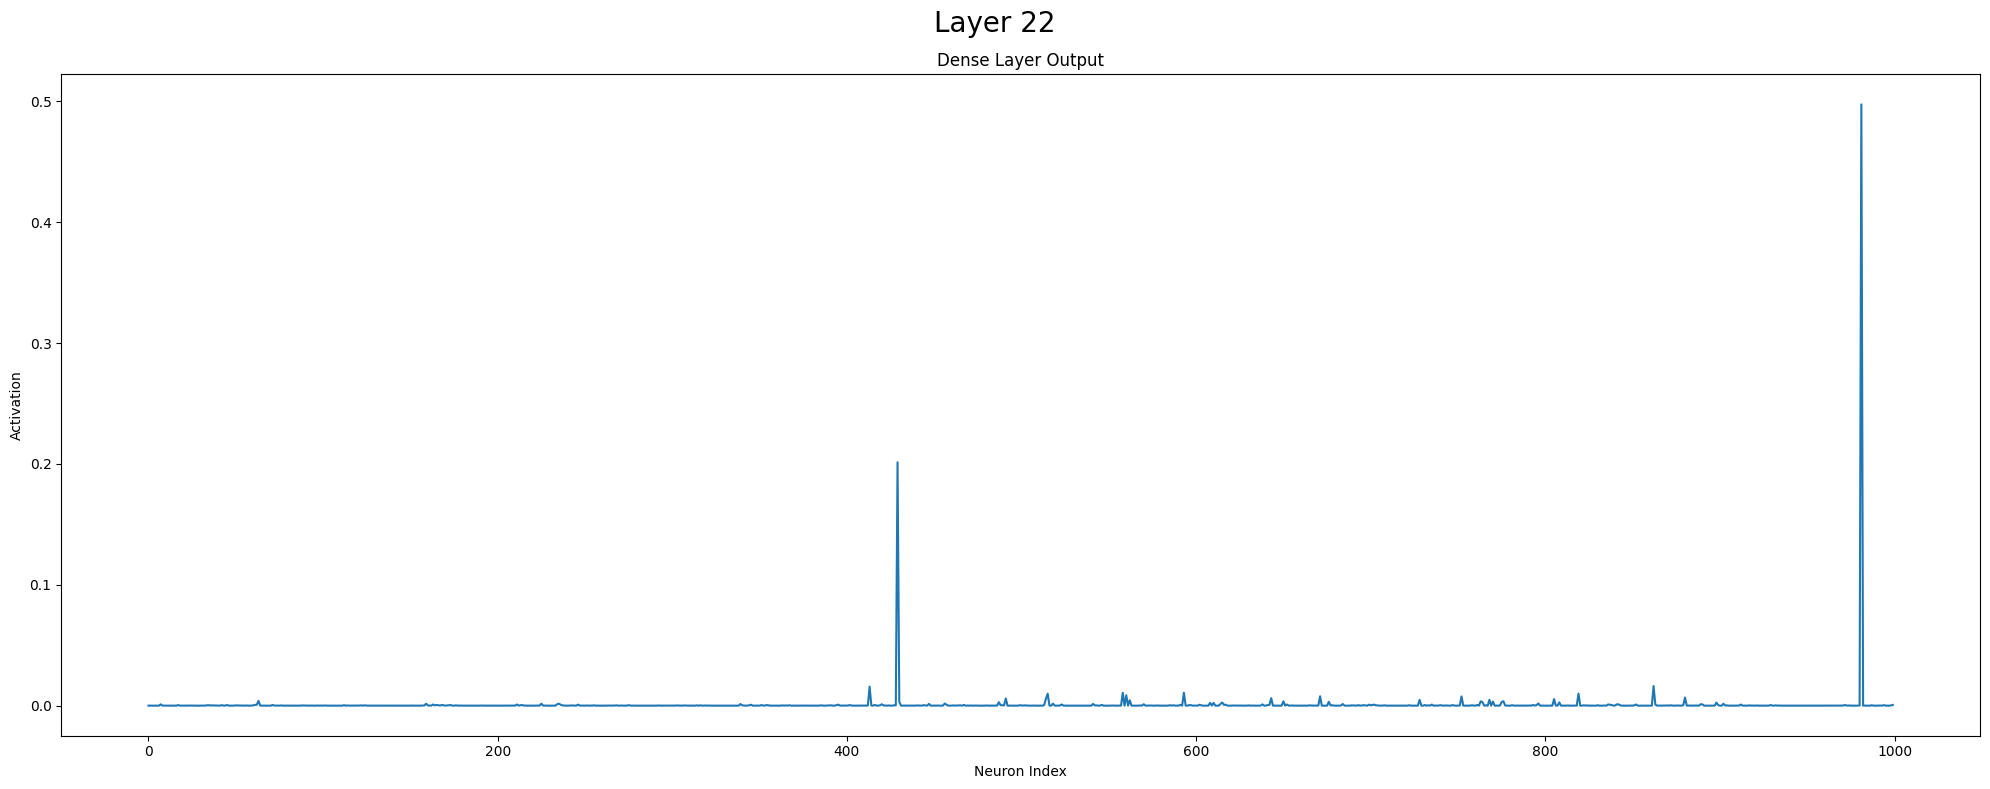

In [14]:
import matplotlib.pyplot as plt
import numpy as np
feature_maps = model3.predict(image)

for idx, fmap in zip(layer_index, feature_maps):
    print(f"Layer {idx} output shape: {fmap.shape}")
    fig = plt.figure(figsize=(20, 8))
    fig.suptitle(f"Layer {idx}", fontsize=20)

    # If convolutional output (4D with shape [1, H, W, C])
    if len(fmap.shape) == 4:
        num_features = fmap.shape[-1]
        for i in range(1, min(num_features, 64) + 1):  # up to 64 channels
            plt.subplot(8, 8, i)
            plt.imshow(fmap[0, :, :, i - 1], cmap='gray')
            plt.axis('off')
    # If dense layer output (2D with shape [1, N])
    elif len(fmap.shape) == 2:
        plt.plot(fmap[0])
        plt.title("Dense Layer Output")
        plt.xlabel("Neuron Index")
        plt.ylabel("Activation")
    else:
        print(f"Unsupported output shape for visualization: {fmap.shape}")

    plt.tight_layout()
    plt.show()

## 🧠 What Is a Dense Layer?

A **Dense layer** (also called a fully connected layer) in neural networks:

* Takes a **1D input vector** (like a list of numbers).
* Multiplies it by a **weight matrix**, adds a **bias**, and passes it through an activation function.
* Outputs another **1D vector** — the activations of neurons in that layer.

---

## 🔍 Why Do You See a Signal or Line Plot?

### Because:

* The output of a Dense layer is a **1D array of numbers**, one number per neuron.
* When you predict an image with a model and extract Dense layer outputs, you get something like this:

  ```
  shape = (1, N)
  ```

  where `N` is the number of neurons.

### Example:

```python
>>> output = model.predict(image)
>>> output.shape
(1, 128)  # 128 neurons in Dense layer
```

You’re visualizing these 128 values — one for each neuron. That’s why the best way to visualize them is:

* **Line plot**: shows how activation changes from neuron to neuron.
* **Bar chart**: compares activations across neurons.

That looks like a **signal graph**, because it is literally a **1D signal** (just like sound waves or ECG signals).

---

## 🔬 Why Can't You Use `imshow()`?

`imshow()` is for 2D data — like an image (e.g., shape `(28, 28)`).

Dense output has shape `(1, N)` → not a 2D image, so `imshow()` fails or gives meaningless output.

---

## 🎨 In Summary

| Layer Type | Output Shape | Visualized As          | Why?                            |
| ---------- | ------------ | ---------------------- | ------------------------------- |
| Conv2D     | (1, H, W, C) | Feature maps (images)  | 2D slices per channel           |
| Dense      | (1, N)       | Line/bar plot (signal) | 1D vector of neuron activations |

---